## Problem Statement

### Context

AllLife Bank is a mid-sized, fast-growing US-based financial institution that offers a range of retail banking services, including savings and checking accounts, fixed deposits, and personal loans. The bank’s business model is centered on building long-term customer relationships, expanding its retail footprint, and growing its loan portfolio to drive sustainable profitability through interest income.

It currently relies on a large base of liability customers (depositors) but faces a significant under-representation of asset customers (borrowers). To drive profitability through interest income, the bank must aggressively expand its loan portfolio by converting existing depositors into personal loan customers.

Last year’s pilot campaign achieved a 9% conversion rate, validating the potential of this strategy. However, to optimize marketing spend and improve efficiency, the retail marketing department requires a more data-driven approach. Enhancing the success ratio of these campaigns is critical for sustainable growth and maximizing customer lifetime value.

### Objective

The objective is to develop a predictive classification model that identifies patterns and key factors driving personal loan adoption among existing liability customers. By uncovering the demographic and behavioral drivers of loan conversion, the goal is to enable targeted segmentation and more precise marketing interventions that improve campaign conversion rates, optimize marketing spend, and enhance overall profitability through higher-quality loan portfolio growth.

### Data Dictionary

* `ID`: Customer ID
* `Age`: Customer’s age in completed years
* `Experience`: #years of professional experience
* `Income`: Annual income of the customer (in thousand dollars)
* `ZIP Code`: Home Address ZIP code.
* `Family`: the Family size of the customer
* `CCAvg`: Average spending on credit cards per month (in thousand dollars)
* `Education`: Education Level. 1: Undergrad; 2: Graduate;3: Advanced/Professional
* `Mortgage`: Value of house mortgage if any. (in thousand dollars)
* `Personal_Loan`: Did this customer accept the personal loan offered in the last campaign? (0: No, 1: Yes)
* `Securities_Account`: Does the customer have securities account with the bank? (0: No, 1: Yes)
* `CD_Account`: Does the customer have a certificate of deposit (CD) account with the bank? (0: No, 1: Yes)
* `Online`: Do customers use internet banking facilities? (0: No, 1: Yes)
* `CreditCard`: Does the customer use a credit card issued by any other Bank (excluding All life Bank)? (0: No, 1: Yes)

## Importing necessary libraries

In [ ]:
# Installing the libraries with the specified version.
!pip install numpy==2.0.2 pandas==2.2.2 matplotlib==3.10.0 seaborn==0.13.2 scikit-learn==1.6.1 sklearn-pandas==2.2.0 -q --user

**Note**:

1. After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab), write the relevant code for the project from the next cell, and run all cells sequentially from the next cell.

2. On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import(
    confusion_matrix,
    accuracy_score,
    recall_score,
    precision_score,
    f1_score,
)

In [ ]:
# mounting google drive onto Google Notebook
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Loading the dataset

In [ ]:
# pulling dataset from google drive path onto Notebook
dataframe=pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Loan_Modelling.csv")

In [ ]:
# creating a copy of the dataset to allow for data manipulation without altering original dataset
df=dataframe.copy()

## Data Overview

* Observations
* Sanity checks

In [ ]:
# sample data from the dataset (first 5 rows and all columns)
df.head()

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIPCode             5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal_Loan       5000 non-null   int64  
 10  Securities_Account  5000 non-null   int64  
 11  CD_Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


In [ ]:
# finding how many rows and columns in the dataset
df.shape

(5000, 14)

In [ ]:
df.describe()

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2500.500000,45.338400,20.104600,73.774200,93169.257000,2.396400,1.937938,1.881000,56.498800,0.096000,0.104400,0.06040,0.596800,0.294000
std,1443.520003,11.463166,11.467954,46.033729,1759.455086,1.147663,1.747659,0.839869,101.713802,0.294621,0.305809,0.23825,0.490589,0.455637
min,1.000000,23.000000,-3.000000,8.000000,90005.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,1250.750000,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,2500.500000,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000
75%,3750.250000,55.000000,30.000000,98.000000,94608.000000,3.000000,2.500000,3.000000,101.000000,0.000000,0.000000,0.00000,1.000000,1.000000
max,5000.000000,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,3.000000,635.000000,1.000000,1.000000,1.00000,1.000000,1.000000


In [ ]:
# Check for identical data with different ID Numbers

duplicated = df.duplicated(subset=['ID'])

print(duplicated.sum())

0


In [ ]:
# find minimum and maximum values for Experience

print('Minimum Value for Experience is',df['Experience'].min())
print('Maximum Value for Experience is', df['Experience'].max())

#Find amount of negative values and create a list of each by ID number
negative_values = df.loc[df['Experience'] < 0, 'Experience']
negative_values_sum = negative_values.count()
print("There are", negative_values_sum, "Negative Values")

Minimum Value for Experience is -3
Maximum Value for Experience is 43
There are 52 Negative Values


In [ ]:
# Check that all family sizes are whole numbers
family_size_whole = df.loc[df['Family'] % 1 != 0, 'Family']
print("Number of families with non whole numbers =",family_size_whole.count())

Number of families with non whole numbers = 0


# Observations

### Dataframe Shape
Has 5000 rows and 14 columns

### Duplicates
No Duplicate ID Numbers

### No Missing Values
There are no missing values in the dataset

### Some users inputted negative experience
The minimum value for experience is -3 years and max is 43 years. There are 75 values in the dataset.

### All family sizes are whole numbers

## Exploratory Data Analysis.

EDA is a critical step in any data project used to investigate and understand the data before model construction.

The following questions serve as a starting point to help you approach the analysis and generate initial insights:

**Questions**:
1. What is the distribution of mortgage attribute? Are there any noticeable patterns or outliers in the distribution?
2. How many customers have credit cards?
3. What are the attributes that have a strong correlation with the target attribute (personal loan)?
4. How does a customer's interest in purchasing a loan vary with their education?
5. How does a customer's interest in purchasing a loan vary with their age?

**[IMPORTANT]** Beyond the Basics: Please note that these are guiding questions only. To receive full points for this rubric section, you are expected to perform a thorough analysis that goes beyond these specific questions to uncover deeper trends and relationships within the data.

# Univariate Analysis

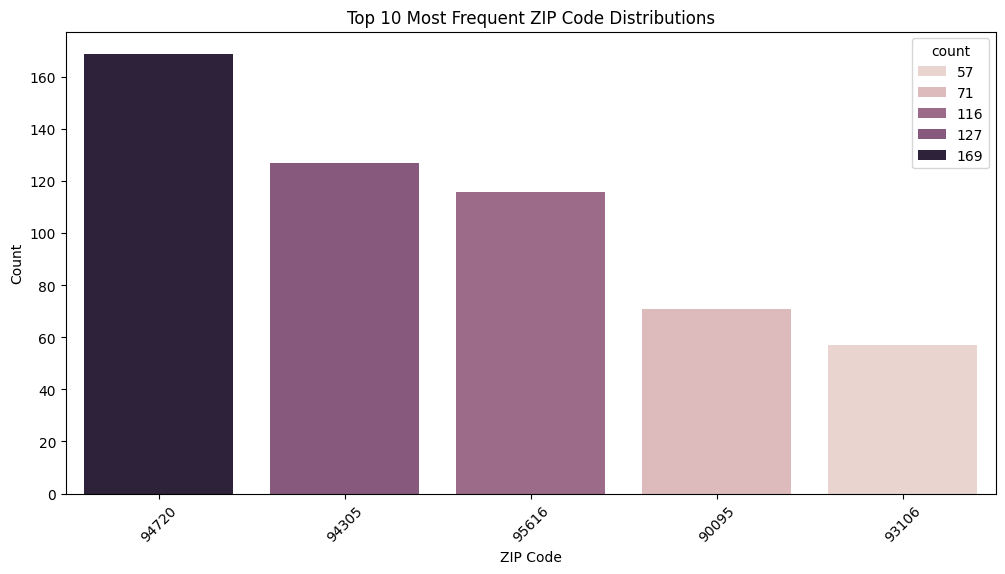

In [ ]:
# Calculate value counts for ZIPCode and get the top 10 most frequent
zip_code_counts = df['ZIPCode'].value_counts().head(5)

# Create a bar plot for the top 10 ZIP codes to clearly label each bar
plt.figure(figsize=(12, 6))
sns.barplot(x=zip_code_counts.index.astype(str), y=zip_code_counts.values, hue=zip_code_counts);
plt.title('Top 10 Most Frequent ZIP Code Distributions')
plt.xlabel('ZIP Code')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

#Observation
Top 5 Zip Codes where our customers live are in the 94720, 94305, 95616, 90095, and 93106 zip codes. There is a heavy right skew of other zip codes.


4


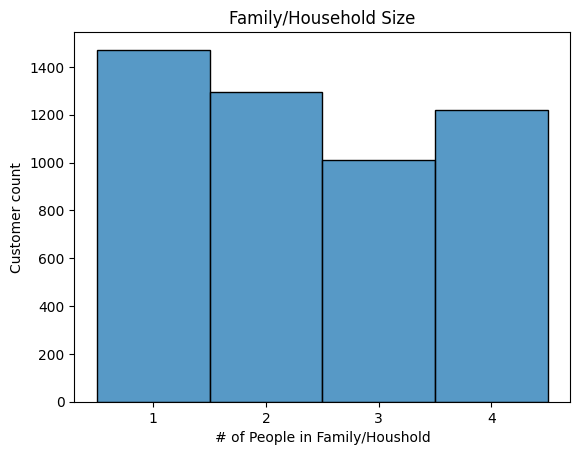

In [ ]:
# Categorize Family size
print(df['Family'].max());
family_data = df['Family'].astype('category');
bins = [1,2,3,4];

#Plot Bar Plot for Family/Household size of customers
sns.histplot(data=family_data, bins=bins, binwidth=15);
plt.xticks(bins);
plt.xlabel('# of People in Family/Houshold');
plt.ylabel('Customer count')
plt.title('Family/Household Size');

#Observation
There is a pretty even distribution of customers with family sizes. The largest majority of customers are single, second is married, 3rd and 4th are in 3 or 4 family homes.

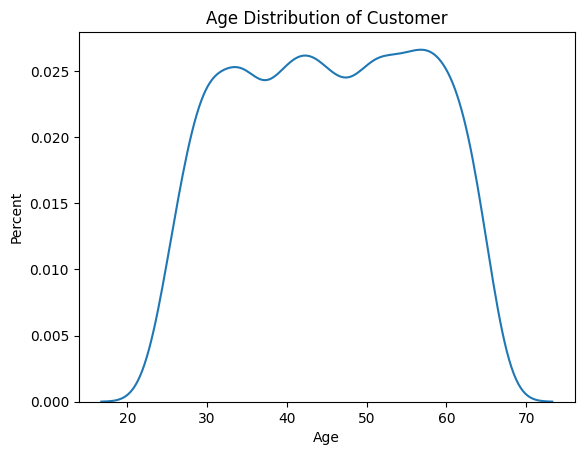

In [ ]:
# Create KDE Plot of age distrubtion of customers
sns.kdeplot(data=df['Age']),;
plt.title('Age Distribution of Customer');
plt.xlabel('Age');
plt.ylabel('Percent');

#Observation
The majority of customers are between the ages of 30 and 60 years old.

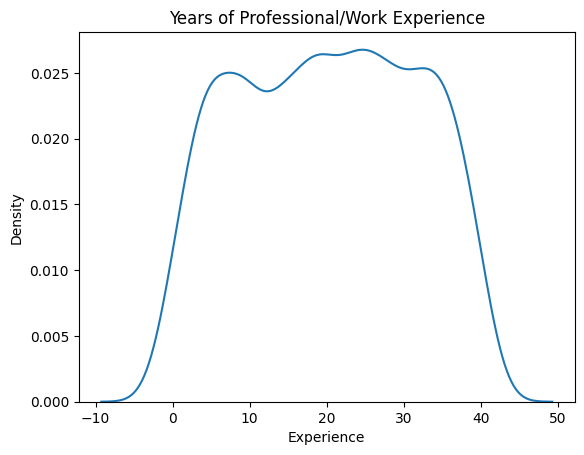

In [ ]:
#KDE plot years of experience
sns.kdeplot(data=df['Experience']);
plt.title('Years of Professional/Work Experience');

#Observation
The majority of customers have between 0 and 40 years of experience. Density is even across this experience level range

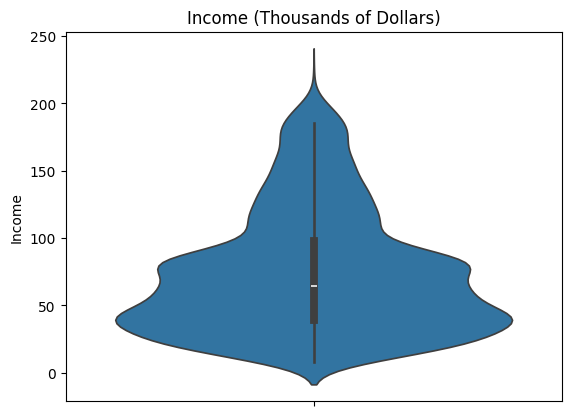

In [ ]:
#Violin Plot of Income of customers
sns.violinplot(data=df['Income']);
plt.title('Income (Thousands of Dollars)');


#Observation
The majority of customers are making roughly 40 to 100k a year. There is a right skew of customers making more than 100k to roughly 250k. Outliers are past 200k.

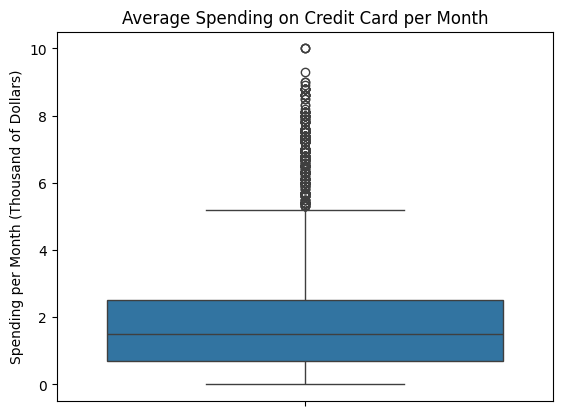

In [ ]:
#Average Spending on Credit card per month Boxplot
sns.boxplot(data=df['CCAvg']);
plt.title('Average Spending on Credit Card per Month');
plt.ylabel('Spending per Month (Thousand of Dollars)');

#Observation
The interquartile range for spending on credit cards is roughly between 500 to 2300 dollars. Heavy right skew of customers spending more than 5300 dollars a month. Large number of outliers past 5300.

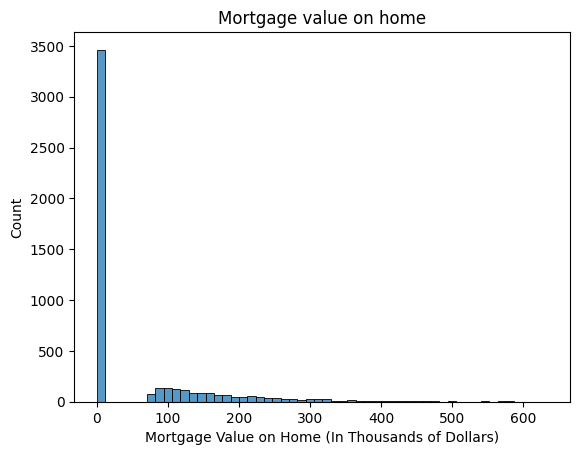

In [ ]:
#Histogram Mortgage value on Home
sns.histplot(data=df['Mortgage']);
plt.title('Mortgage value on home');
plt.xlabel('Mortgage Value on Home (In Thousands of Dollars)');


#Observation
Large number of customers who don't have a mortgage. These values are 0. Majority of mortgages are between 700k to 150k. Heavy right skew

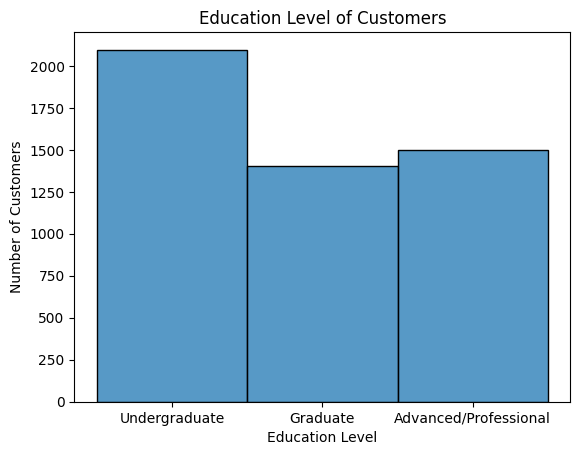

In [ ]:
#Categorize values for Education Level (1 Undergrad, 2 Graduate, 3 Advanced/Professional)
education_data=df['Education'].astype('category')

#Rename category number to the correct name
education_map = {1: 'Undergraduate', 2: 'Graduate',3: 'Advanced/Professional'}

#Map values and assign to data
education_data = education_data.map(education_map).astype('category')

#Create histogram for edducation Level
sns.histplot(data=education_data);
plt.title('Education Level of Customers');
plt.ylabel('Number of Customers');
plt.xlabel('Education Level');


More customers have an undergrad degree vs a graduate level of education. Suprisingly more people have advanced/professional experience vs a graduate degree.

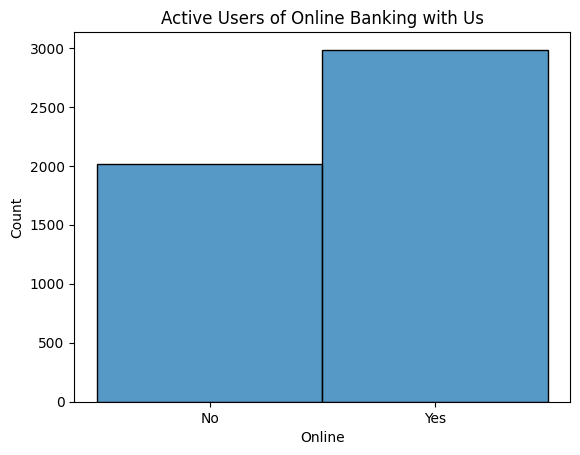

In [ ]:
# seperate online banking data
online_banking_data = df['Online']

# Assign Yes No to 0 and 1
online_banking_map = {0:'No', 1:'Yes'}

#Map values to data
online_banking_data = online_banking_data.map(online_banking_map).astype('category')

#Create Histogram of Customers who use online banking services with our bank
sns.histplot(data=online_banking_data);
plt.title('Active Users of Online Banking with Us');

#Observation
Roughly 3000 users use online banking and 2000 don't.

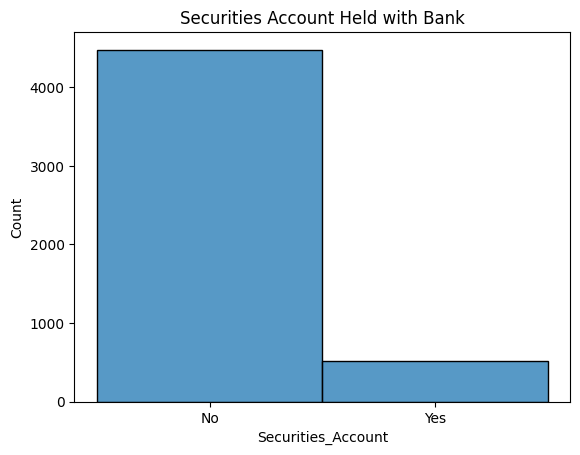

In [ ]:
# Create Copy of Securities Account Data
securities_account_data = df['Securities_Account']

#Assign Yes and No values to 0 and 1
securities_account_map = {0:'No', 1:'Yes'}

#Map Values to Data
securities_account_data = securities_account_data.map(securities_account_map).astype('category')

#plot histogram of Securities Account holdings with Bank
sns.histplot(data=securities_account_data);
plt.title('Securities Account Held with Bank');

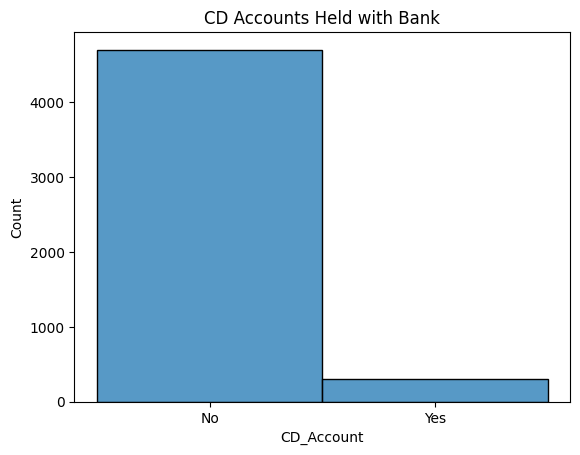

In [ ]:
# create copy of CD_Account Data
CD_account_data = df['CD_Account']

# Assign Yes No values to 0 and 1
CD_account_map = {0:'No', 1:'Yes'}

# Map values to data
CD_account_data = CD_account_data.map(CD_account_map).astype('category')

#Create Historgram of CD Account Data with Bank
sns.histplot(data=CD_account_data);
plt.title('CD Accounts Held with Bank');

Text(0.5, 1.0, 'Customers Who Hold a Credit Card with Another Bank')

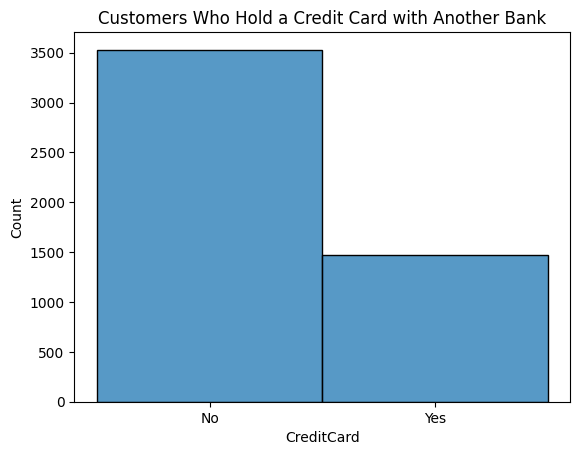

In [ ]:
#create copy of data customers with a credit card with ANOTHER bank
other_credit_card_data = df['CreditCard']

#Assign Yes NO to 0 and 1
other_credit_card_map = {0:'No', 1:'Yes'}

#Map values to copy of data
other_credit_card_data = other_credit_card_data.map(other_credit_card_map).astype('category')

#Create a histogram of customers who hold a credit card with another bank
sns.histplot(data=other_credit_card_data);
plt.title('Customers Who Hold a Credit Card with Another Bank')

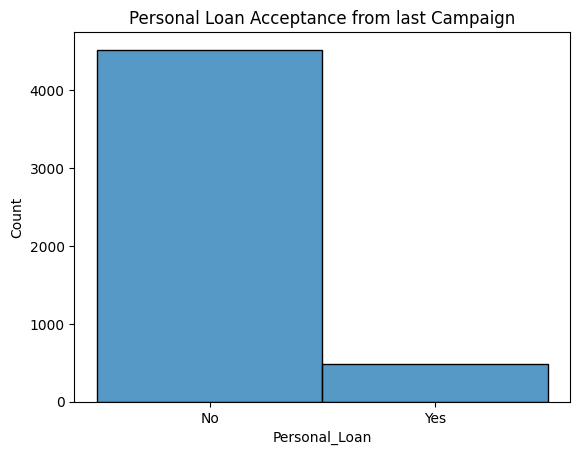

In [ ]:
#Create copy of personal Loan Data
personal_loan_data =df['Personal_Loan'];

#Assign Yes no Values to 0 and 1 Values
personal_loan_map = {0:'No',1:'Yes'};

#Map the values to copy of personal Loan Data
personal_loan_data = personal_loan_data.map(personal_loan_map).astype('category');

#Create Histogram of personal Loan Data
sns.histplot(data=personal_loan_data);
plt.title('Personal Loan Acceptance from last Campaign');



#Observation
Data looks very similar between those who have a securities account with another bank, CD holders, Customers who hold a credit card with another bank, and those approved for a loan in the last campaign.

#Bivariate Analysis

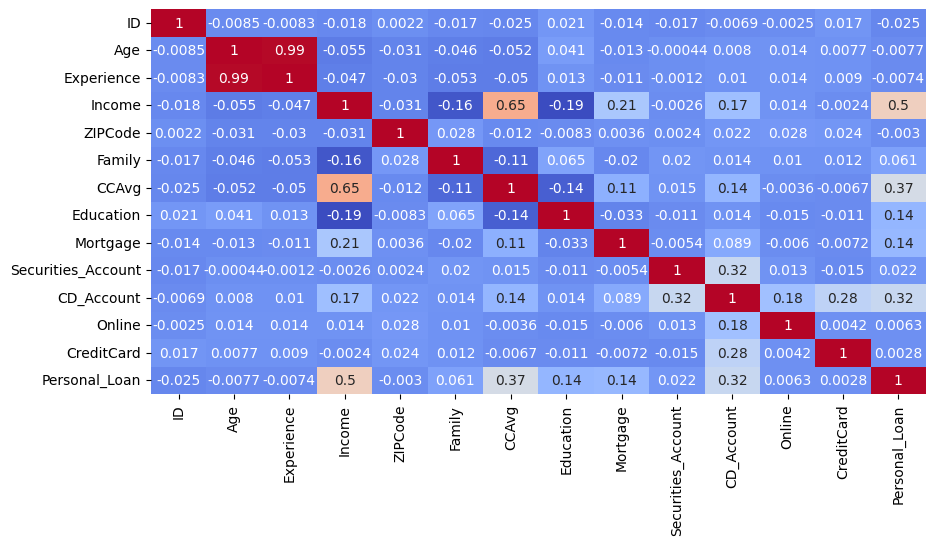

In [ ]:
#reorder so Personal_Loan Variable is at the end in positon -1
cols=list(df.columns)

cols.remove('Personal_Loan')

cols.insert(13, 'Personal_Loan') # Corrected: 'Personal_Loan' instead of 'Personal_loan'

df = df[cols]

#heatmap to see correlation of all variables to the target attribute (Personal Loan)
plt.figure(figsize=(10,5))
sns.heatmap(data=df.corr(),annot=True, cbar=False, cmap='coolwarm');

#Observation
There is a .99 correlation between experience and age. Because of this we will drop experience from the dataset.

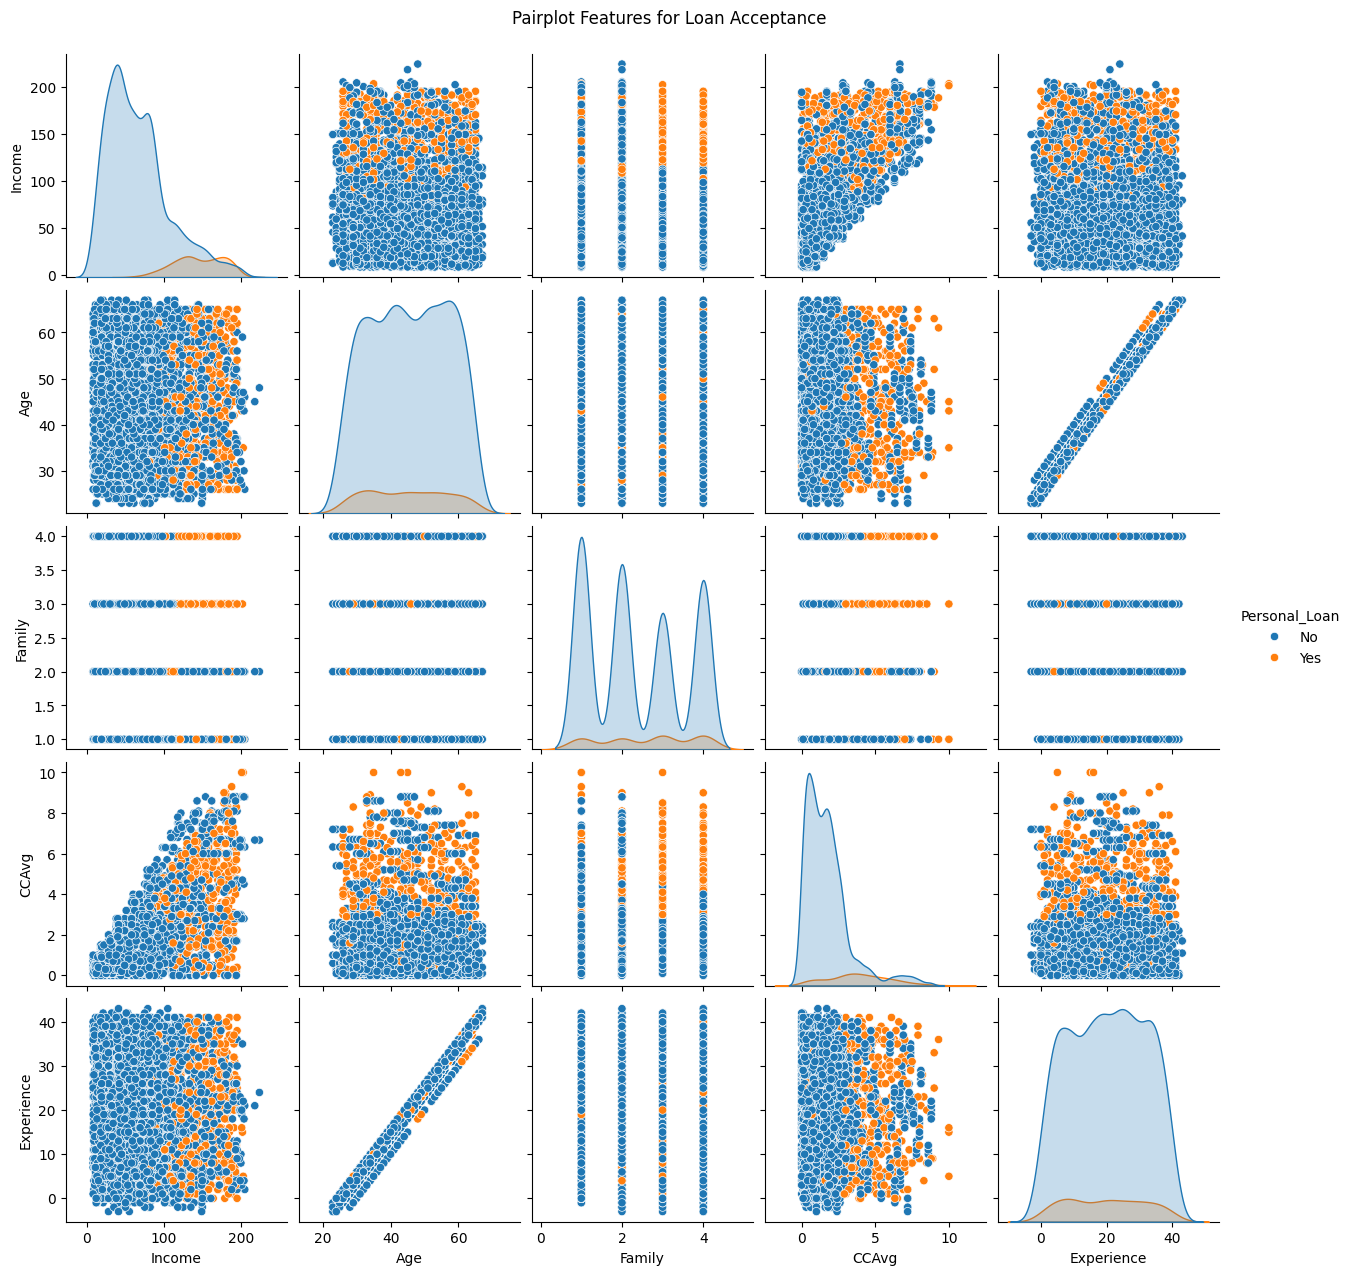

In [ ]:
# Combine Series into a single DataFrame for the features
plot_df = pd.DataFrame({
    'Income': df['Income'],
    'Age': df['Age'],
    'Family': df['Family'],
    'CCAvg': df['CCAvg'],
    'Experience': df['Experience'],
    'Personal_Loan': personal_loan_data
})

# Create the pairplot with the DataFrame and use the Personal_Loan column for hue
sns.pairplot(data=plot_df, hue='Personal_Loan', diag_kind='kde')
plt.suptitle('Pairplot Features for Loan Acceptance', y=1.02)
plt.show()

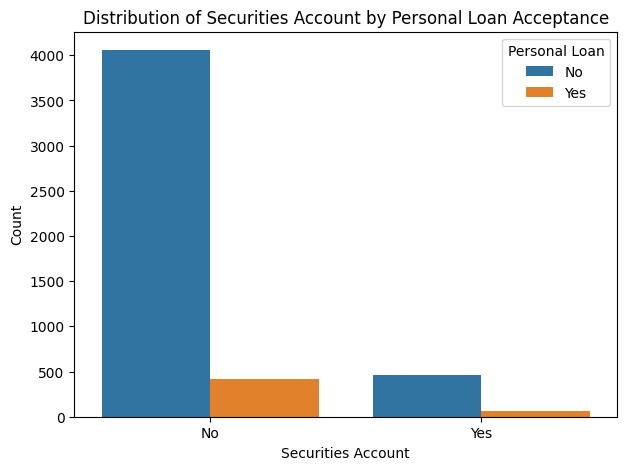

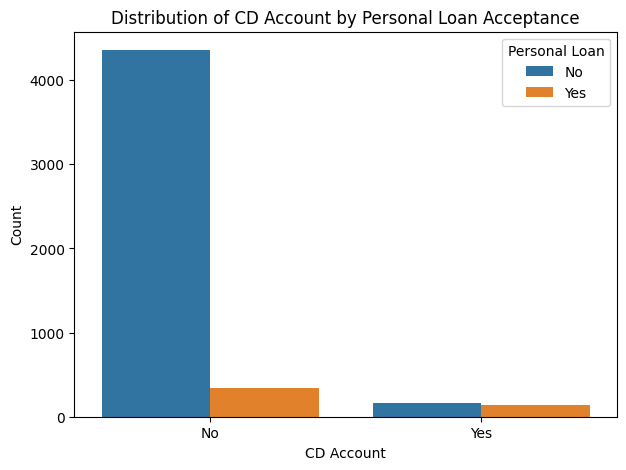

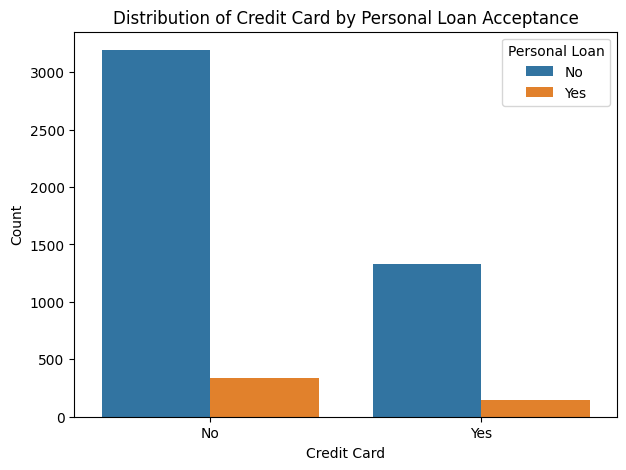

In [ ]:
# Combine Series into a single dataframe, data already converted to categorical data from univariate analysis plots
plot_data_df = pd.DataFrame({
    'Securities Account': securities_account_data,
    'CD Account': CD_account_data,
    'Credit Card': other_credit_card_data,
    'Personal Loan': personal_loan_data
})

# List of column names to input into column attribute in plotting x variable
column_names = ['Securities Account', 'CD Account', 'Credit Card']

# Create a countplot for each feature against Personal_Loan
for col in column_names:
    plt.figure(figsize=(7, 5)) # Create a new figure for each plot
    sns.countplot(data=plot_data_df, x=col, hue='Personal Loan')
    plt.title(f'Distribution of {col} by Personal Loan Acceptance')
    plt.xlabel(col)
    plt.ylabel('Count')
    #plt.show()

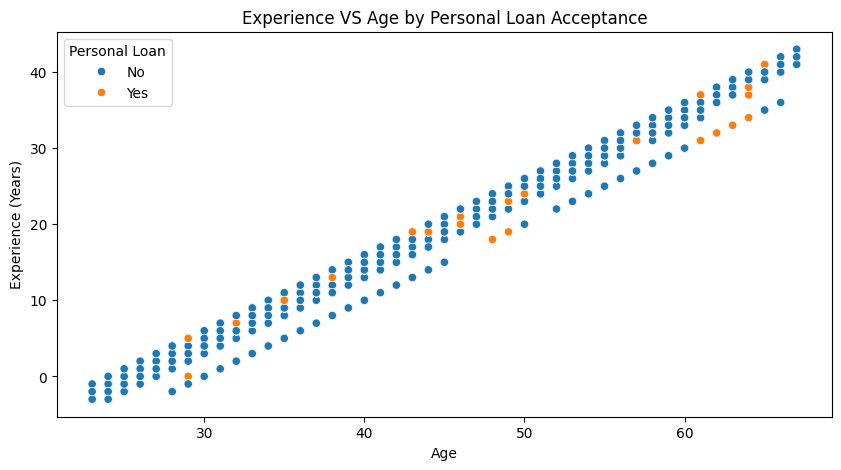

In [ ]:
#Combine Series into a single datframe for age, experience, and personal loan acceptance
plt_df = pd.DataFrame({
    'Age': df['Age'],
    'Experience': df['Experience'],
    'Personal Loan': personal_loan_data # Use the pre-processed categorical 'Yes'/'No' series
})

# Make Histogram of Experience by personal Loan Acceptance
plt.figure(figsize=(10, 5));
sns.scatterplot(data=plt_df, x='Age', y='Experience', hue='Personal Loan');
plt.title('Experience VS Age by Personal Loan Acceptance');
plt.xlabel('Age');
plt.ylabel('Experience (Years)');

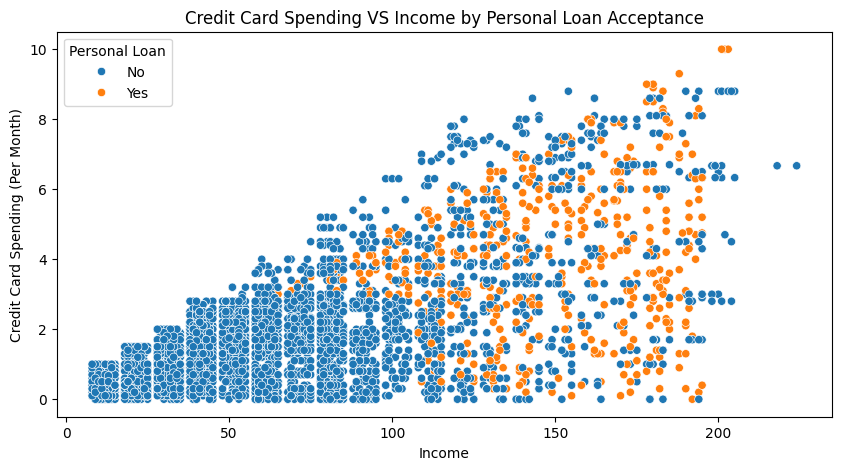

In [ ]:
#(Income, CCAvg, Personal_Loan)
#Combine Series into a single datframe for age, experience, and personal loan acceptance
plt_df = pd.DataFrame({
    'Income': df['Income'],
    'Credit Card Spending Per Month': df['CCAvg'],
    'Personal Loan': personal_loan_data # Use the pre-processed categorical 'Yes'/'No' series
})

# Make Histogram of Credit Card Spending VS Income by personal Loan Acceptance
plt.figure(figsize=(10, 5));
sns.scatterplot(data=plt_df, x='Income', y='Credit Card Spending Per Month', hue='Personal Loan');
plt.title('Credit Card Spending VS Income by Personal Loan Acceptance');
plt.xlabel('Income');
plt.ylabel('Credit Card Spending (Per Month)');

## Data Preprocessing

* Missing value treatment
* Feature engineering (if needed)
* Outlier detection and treatment (if needed)
* Preparing data for modeling
* Any other preprocessing steps (if needed)

In [ ]:
#To Address highly right scewed data in Mortgages, Create a binary indicator variable called Has_Mortgage, Where 1 if has mortgage else 0
df['Has_Mortgage'] = (df['Mortgage'] > 0).astype(int)
df['Mortgage_Amount'] = df['Mortgage']

In [ ]:
#Drop irrelevant ID-like columns like ID and Zip Code, Also Drop Mortgage and Experience as they are repetitive
X = df.drop(['ID','ZIPCode','Experience','Mortgage','Personal_Loan'], axis=1)
#Seperate Y Data Personal_Loan (acceptance)
Y = df['Personal_Loan']

In [ ]:
#create dummy variables to see categorical columns as binary variables (Encoding)
X = pd.get_dummies(X, columns=['Securities_Account','CD_Account','Online','CreditCard','Has_Mortgage'], drop_first=True)
X = X.astype(float)

#Key Insight
Given that the Mortgage data was heavily right skewed due to those who carry no Mortgage, I created two new columns one a binary whether they do or don't have a mortgage and the second a float value of how much their mortgage is. I then dropped the original mortgage column as it became redundant.

#Outliers
I removed the Experience column as it was redundant and had a 99% correlation to Age. This also solved the problem of there being negative values in the Experience data. These were likely incorrect entries as experience can't be a value less than 0.

#Missing Values
No missing values

#Feature Engineering
Created Encoded columsn for categorical data, removed non needed columns such as ID, ZipCode, Experience, Mortgage.



In [ ]:
X.head()

,Age,Income,Family,CCAvg,Education,Mortgage_Amount,Securities_Account_1,CD_Account_1,Online_1,CreditCard_1,Has_Mortgage_1
0,25.0,49.0,4.0,1.6,1.0,0.0,1.0,0.0,0.0,0.0,0.0
1,45.0,34.0,3.0,1.5,1.0,0.0,1.0,0.0,0.0,0.0,0.0
2,39.0,11.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,35.0,100.0,1.0,2.7,2.0,0.0,0.0,0.0,0.0,0.0,0.0
4,35.0,45.0,4.0,1.0,2.0,0.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
#Split the data in an 80:20 ratio for train and test sets
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.20, stratify=Y, random_state=42)

In [ ]:
print("Shape of training set:", X_train.shape)
print("Shape of test set:", X_test.shape)
print("Percentage of classes in training set:")
print(100*Y_train.value_counts(normalize=True))
print("Percentage of classes in test set:")
print(100*Y_test.value_counts(normalize=True))


Shape of training set: (4000, 11)
Shape of test set: (1000, 11)
Percentage of classes in training set:
Personal_Loan
0    90.4
1     9.6
Name: proportion, dtype: float64
Percentage of classes in test set:
Personal_Loan
0    90.4
1     9.6
Name: proportion, dtype: float64


## Model Building

### Model Building

#Decision Tree1
Default SKLearn Decision Tree

In [ ]:
#creating an instance of the decision tree model
dtree1 = DecisionTreeClassifier(random_state=42)

# Fitting the model to the training data
dtree1.fit(X_train, Y_train)

DecisionTreeClassifier(random_state=42)

In [ ]:
# defining a function to compute different metrics to check performance of a classification model
def model_performance_classification(model, predictors, target):

  #predicting using the independent variables
  pred = model.predict(predictors)

  acc = accuracy_score(target, pred)
  recall = recall_score(target, pred)
  precision = precision_score(target, pred)
  f1 = f1_score(target, pred)

  #creating a dataframe of metrics
  df_perf = pd.DataFrame(
      {'Accuracy:': acc, 'Recall:': recall, 'Precision:':precision, 'F1:': f1,},
      index=[0]
  )

  return df_perf

In [ ]:
def plot_confusion_matrix(model, predictors, target):

    # Predict the target values using the provided model and predictors
    y_pred = model.predict(predictors)

    # Compute the confusion matrix comparing the true target values with the predicted values
    cm = confusion_matrix(target, y_pred)

    # Create labels for each cell in the confusion matrix with both count and percentage
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)    # reshaping to a matrix

    # Set the figure size for the plot
    plt.figure(figsize=(6, 4))

    # Plot the confusion matrix as a heatmap with the labels
    sns.heatmap(cm, annot=labels, fmt="")

    # Add a label to the y-axis
    plt.ylabel("True label")

    # Add a label to the x-axis
    plt.xlabel("Predicted label")

#Decision Tree 1 Performance Metrics

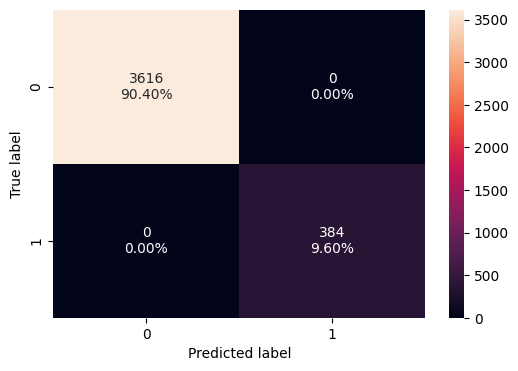

In [ ]:
plot_confusion_matrix(dtree1, X_train, Y_train)

In [ ]:
model_performance_classification(dtree1, X_train, Y_train)

,Accuracy:,Recall:,Precision:,F1:
0,1.0,1.0,1.0,1.0


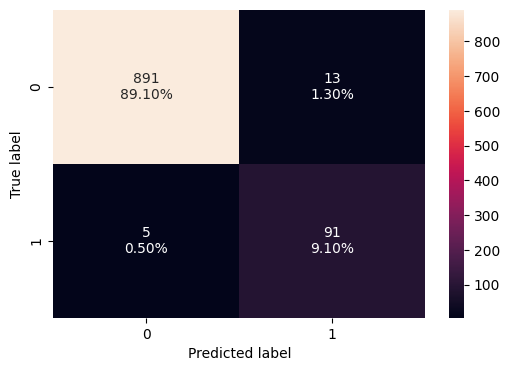

In [ ]:
plot_confusion_matrix(dtree1, X_test, Y_test )

In [ ]:
model_performance_classification(dtree1, X_test, Y_test)

,Accuracy:,Recall:,Precision:,F1:
0,0.982,0.947917,0.875,0.91


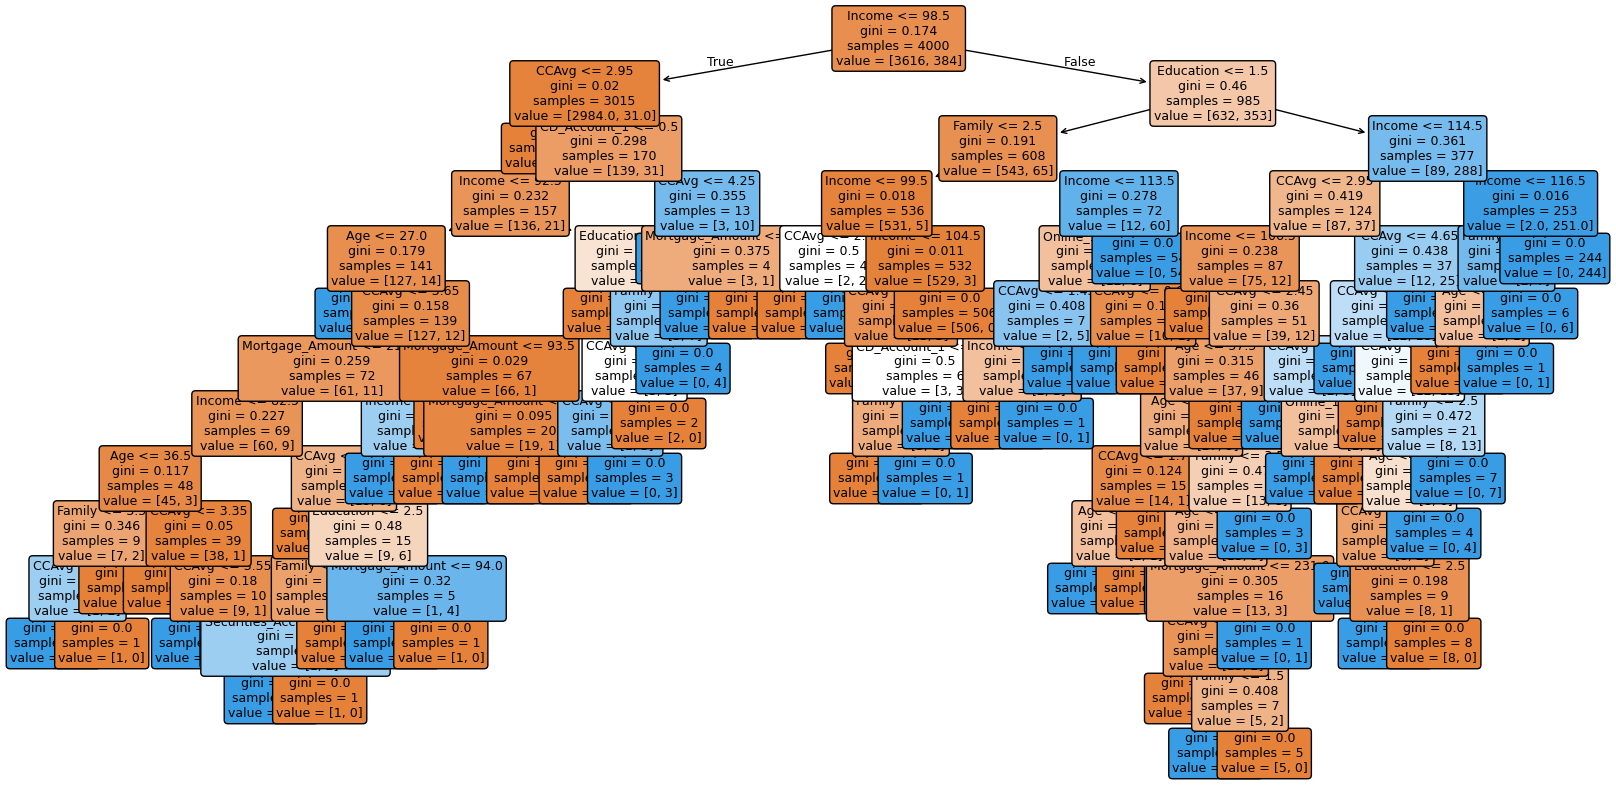

In [ ]:
import sklearn.tree as tree

#visualize decision tree 1
plt.figure(figsize=(20,10))
tree.plot_tree(dtree1, feature_names=X_train.columns, fontsize=9, filled=True, rounded=True)
plt.show()

#Decision Tree 1 Observation
Overfitted the data. Needs to be pruned.

## Model Performance Improvement

In [ ]:
# define the parameters of the tree to iterate over
max_depth_values = np.arange(2, 11, 2)
max_leaf_nodes_values = np.arange(10, 51, 10)
min_samples_split_values = np.arange(10, 51, 10)

# initialize variables to store the best model and its performance
best_estimator = None
best_score_diff = float('inf')

# iterate over all combinations of the specified parameter values
for max_depth in max_depth_values:
    for max_leaf_nodes in max_leaf_nodes_values:
        for min_samples_split in min_samples_split_values:

            # initialize the tree with the current set of parameters
            estimator = DecisionTreeClassifier(
                max_depth=max_depth,
                max_leaf_nodes=max_leaf_nodes,
                min_samples_split=min_samples_split,
                random_state=42
            )

            # fit the model to the training data
            estimator.fit(X_train, Y_train)

            # make predictions on the training and test sets
            y_train_pred = estimator.predict(X_train)
            y_test_pred = estimator.predict(X_test)

            # calculate precision scores for training and test sets
            train_precision_score = precision_score(Y_train, y_train_pred)
            test_precision_score = precision_score(Y_test, y_test_pred)

            # calculate the absolute difference between training and test precision scores
            score_diff = abs(train_precision_score - test_precision_score)

            # update the best estimator and best score if the current one has a smaller score difference
            if score_diff < best_score_diff:
                best_score_diff = score_diff
                best_estimator = estimator

#Decision Tree 2 Pre-Pruned for Optimal Precision Score
Decision Tree 2 finds the best hyperperameter to give the least difference between the training precision score and test precision score

In [ ]:
# creating an instance of the best model
dtree2 = best_estimator

# fitting the best model to the training data
dtree2.fit(X_train, Y_train)

DecisionTreeClassifier(max_depth=np.int64(4), max_leaf_nodes=np.int64(10),
                       min_samples_split=np.int64(10), random_state=42)

In [ ]:
model_performance_classification(dtree2, X_train, Y_train)

,Accuracy:,Recall:,Precision:,F1:
0,0.98475,0.885417,0.952381,0.917679


#Decision Tree 2 Performance Metrics

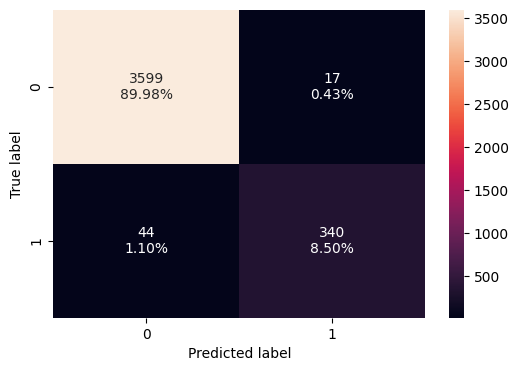

In [ ]:
plot_confusion_matrix(dtree2, X_train, Y_train)

In [ ]:
model_performance_classification(dtree2, X_test, Y_test)

,Accuracy:,Recall:,Precision:,F1:
0,0.991,0.958333,0.948454,0.953368


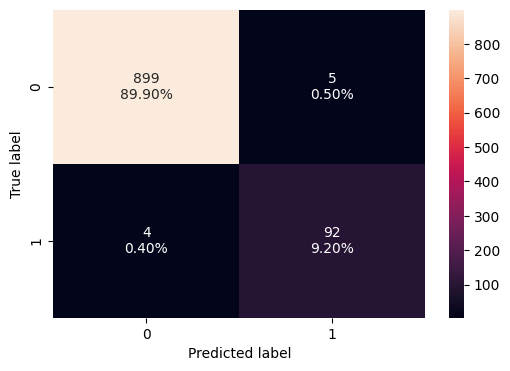

In [ ]:
plot_confusion_matrix(dtree2, X_test, Y_test)

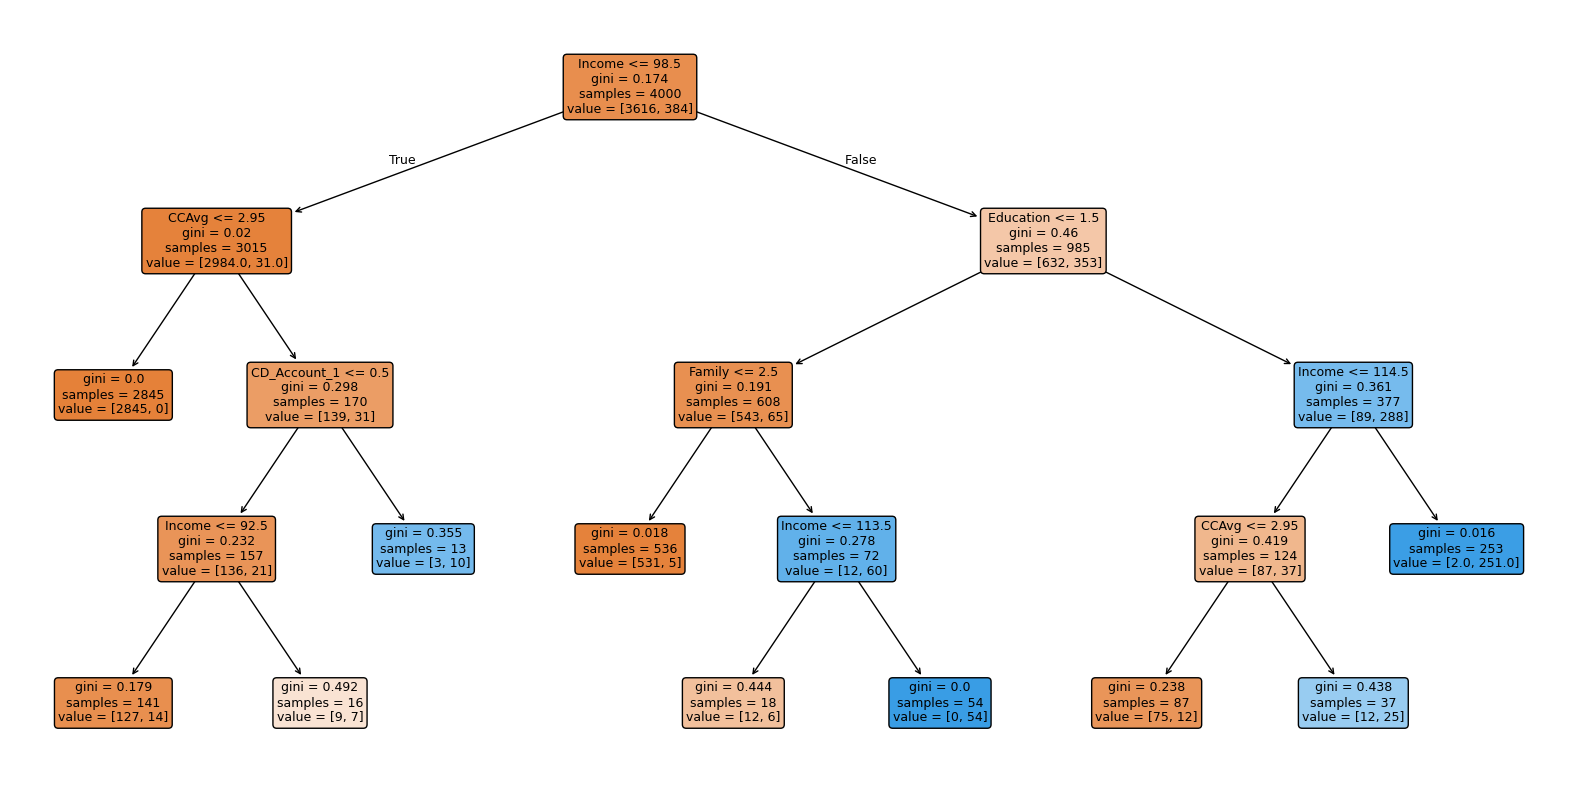

In [ ]:
import sklearn.tree as tree

#visualize decision tree 2
plt.figure(figsize=(20,10))
tree.plot_tree(dtree2, feature_names=X_train.columns, fontsize=9, filled=True, rounded=True)
plt.show()

In [ ]:
# Create an instance of the decision tree model
clf = DecisionTreeClassifier(random_state=42)

# Compute the cost complexity pruning path for the model using the training data
path = clf.cost_complexity_pruning_path(X_train, Y_train)

# Extract the array of effective alphas from the pruning path
ccp_alphas = abs(path.ccp_alphas)

# Extract the array of total impurities at each alpha along the pruning path
impurities = path.impurities

In [ ]:
pd.DataFrame(path)

,ccp_alphas,impurities
0,0.000000,0.000000
1,0.000233,0.000467
2,0.000244,0.000954
3,0.000246,0.001446
4,0.000300,0.002046
5,0.000306,0.002965
6,0.000331,0.003958
7,0.000333,0.004291
8,0.000333,0.004624
9,0.000333,0.004958


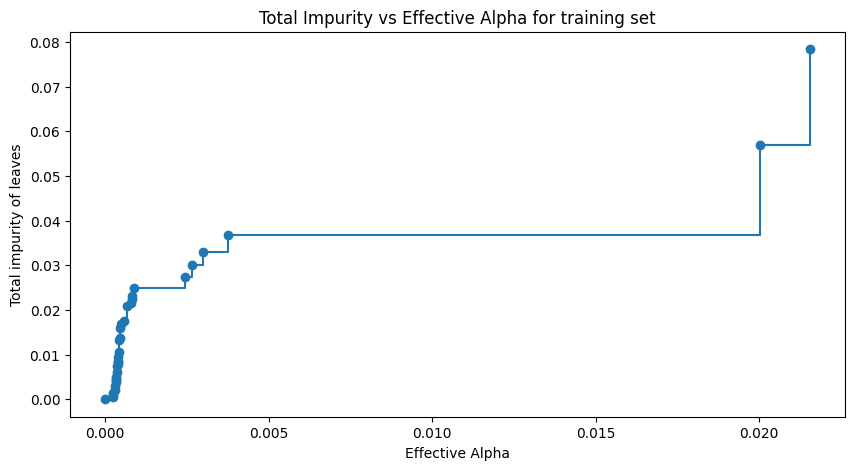

In [ ]:
# Create a figure
fig, ax = plt.subplots(figsize=(10, 5))

# Plot the total impurities versus effective alphas, excluding the last value,
# using markers at each data point and connecting them with steps
ax.plot(ccp_alphas[:-1], impurities[:-1], marker="o", drawstyle="steps-post")

# Set the x-axis label
ax.set_xlabel("Effective Alpha")

# Set the y-axis label
ax.set_ylabel("Total impurity of leaves")

# Set the title of the plot
ax.set_title("Total Impurity vs Effective Alpha for training set");

In [ ]:
# Initialize an empty list to store the decision tree classifiers
clfs = []

# Iterate over each ccp_alpha value extracted from cost complexity pruning path
for ccp_alpha in ccp_alphas:
    # Create an instance of the DecisionTreeClassifier
    clf = DecisionTreeClassifier(ccp_alpha=ccp_alpha, random_state=42)

    # Fit the classifier to the training data
    clf.fit(X_train, Y_train)

    # Append the trained classifier to the list
    clfs.append(clf)

# Print the number of nodes in the last tree along with its ccp_alpha value
print(
    "Number of nodes in the last tree is {} with ccp_alpha {}".format(
        clfs[-1].tree_.node_count, ccp_alphas[-1]
    )
)

Number of nodes in the last tree is 1 with ccp_alpha 0.04760359071815693


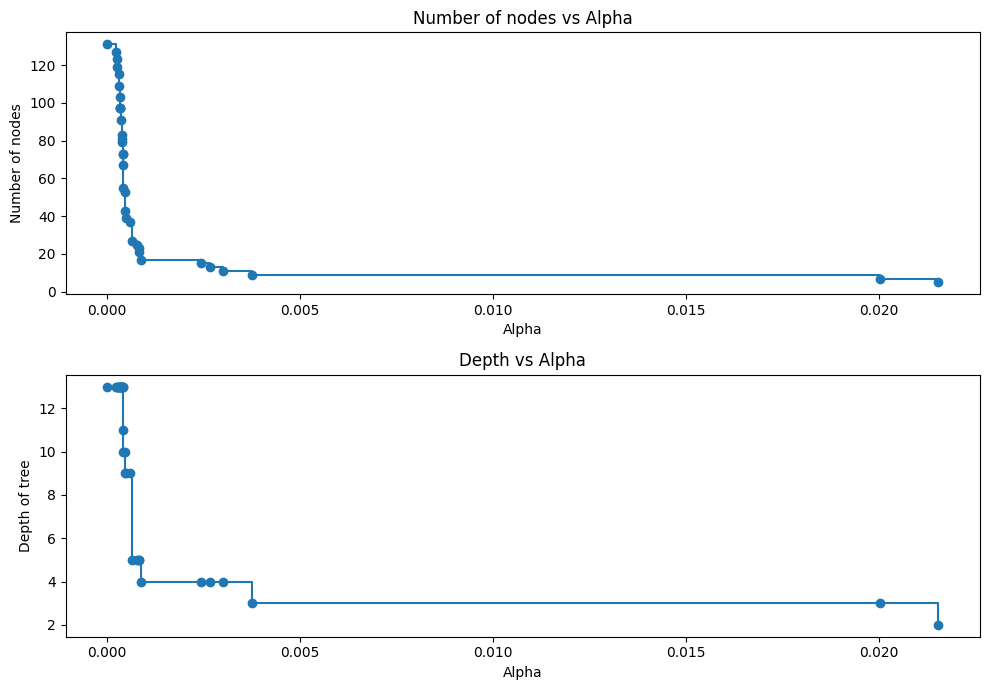

In [ ]:
# Remove the last classifier and corresponding ccp_alpha value from the lists
clfs = clfs[:-1]
ccp_alphas = ccp_alphas[:-1]

# Extract the number of nodes in each tree classifier
node_counts = [clf.tree_.node_count for clf in clfs]

# Extract the maximum depth of each tree classifier
depth = [clf.tree_.max_depth for clf in clfs]

# Create a figure and a set of subplots
fig, ax = plt.subplots(2, 1, figsize=(10, 7))

# Plot the number of nodes versus ccp_alphas on the first subplot
ax[0].plot(ccp_alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_xlabel("Alpha")
ax[0].set_ylabel("Number of nodes")
ax[0].set_title("Number of nodes vs Alpha")

# Plot the depth of tree versus ccp_alphas on the second subplot
ax[1].plot(ccp_alphas, depth, marker="o", drawstyle="steps-post")
ax[1].set_xlabel("Alpha")
ax[1].set_ylabel("Depth of tree")
ax[1].set_title("Depth vs Alpha")

# Adjust the layout of the subplots to avoid overlap
fig.tight_layout()

In [ ]:
train_precision_scores = []  # Initialize an empty list to store precision scores for training set for each decision tree classifier

# Iterate through each decision tree classifier in 'clfs'
for clf in clfs:
    # Predict labels for the training set using the current decision tree classifier
    pred_train = clf.predict(X_train)

    # Calculate the precision score for the training set predictions compared to true labels
    precision_train = precision_score(Y_train, pred_train)

    # Append the calculated precision score to the train_precision_scores list
    train_precision_scores.append(precision_train)

In [ ]:
test_precision_scores = []  # Initialize an empty list to store precision scores for training set for each decision tree classifier

# Iterate through each decision tree classifier in 'clfs'
for clf in clfs:
    # Predict labels for the training set using the current decision tree classifier
    pred_test = clf.predict(X_test)

    # Calculate the F1 score for the training set predictions compared to true labels
    precision_test = precision_score(Y_test, pred_test)

    # Append the calculated F1 score to the train_f1_scores list
    test_precision_scores.append(precision_test)

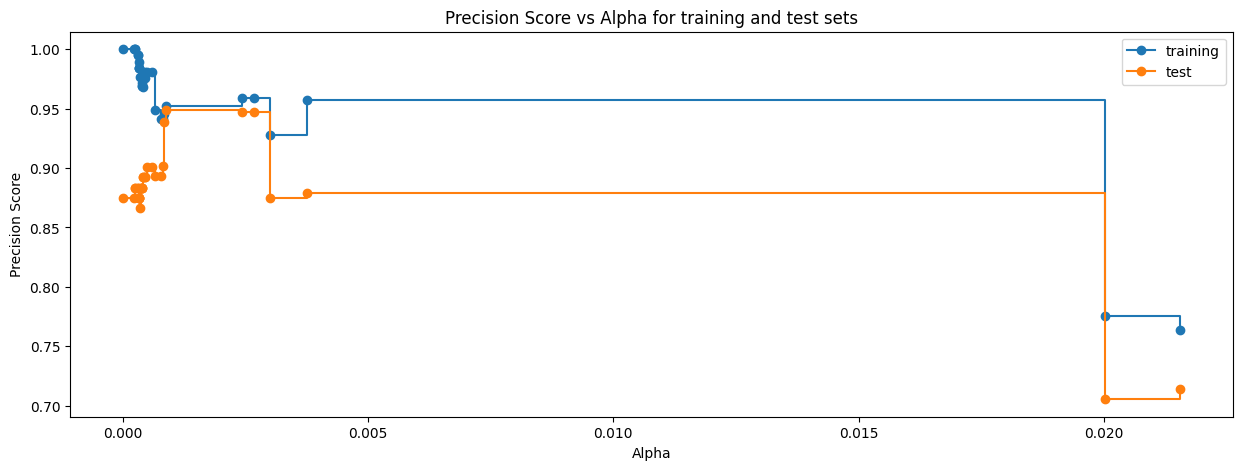

In [ ]:
# Create a figure
fig, ax = plt.subplots(figsize=(15, 5))
ax.set_xlabel("Alpha")  # Set the label for the x-axis
ax.set_ylabel("Precision Score")  # Set the label for the y-axis
ax.set_title("Precision Score vs Alpha for training and test sets")  # Set the title of the plot

# Plot the training precision scores against alpha, using circles as markers and steps-post style
ax.plot(ccp_alphas, train_precision_scores, marker="o", label="training", drawstyle="steps-post")

# Plot the testing precision scores against alpha, using circles as markers and steps-post style
ax.plot(ccp_alphas, test_precision_scores, marker="o", label="test", drawstyle="steps-post")

ax.legend();  # Add a legend to the plot

#Decision Tree 3 Post-
Tree 3 was allowed to grow fully, then leaves were trimmed off when found not to improve performance. This reduced overfitting.

In [ ]:
# creating the model where we get highest test precision Score
index_best_model = np.argmax(test_precision_scores)

# selcting the decision tree model corresponding to the highest test score
dtree3 = clfs[index_best_model]
dtree3

DecisionTreeClassifier(ccp_alpha=np.float64(0.0008702884311333967),
                       random_state=42)

#Decision Tree 3 Performance Metrics

In [ ]:
model_performance_classification(dtree3, X_train, Y_train)

,Accuracy:,Recall:,Precision:,F1:
0,0.98475,0.885417,0.952381,0.917679


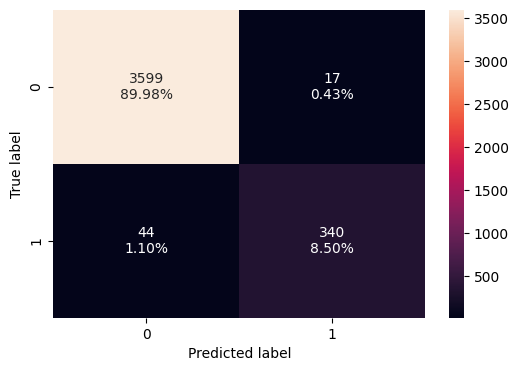

In [ ]:
plot_confusion_matrix(dtree3, X_train, Y_train)

In [ ]:
model_performance_classification(dtree3, X_test, Y_test)

,Accuracy:,Recall:,Precision:,F1:
0,0.991,0.958333,0.948454,0.953368


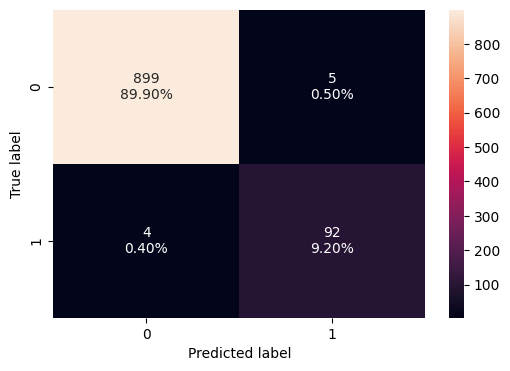

In [ ]:
plot_confusion_matrix(dtree3, X_test, Y_test)

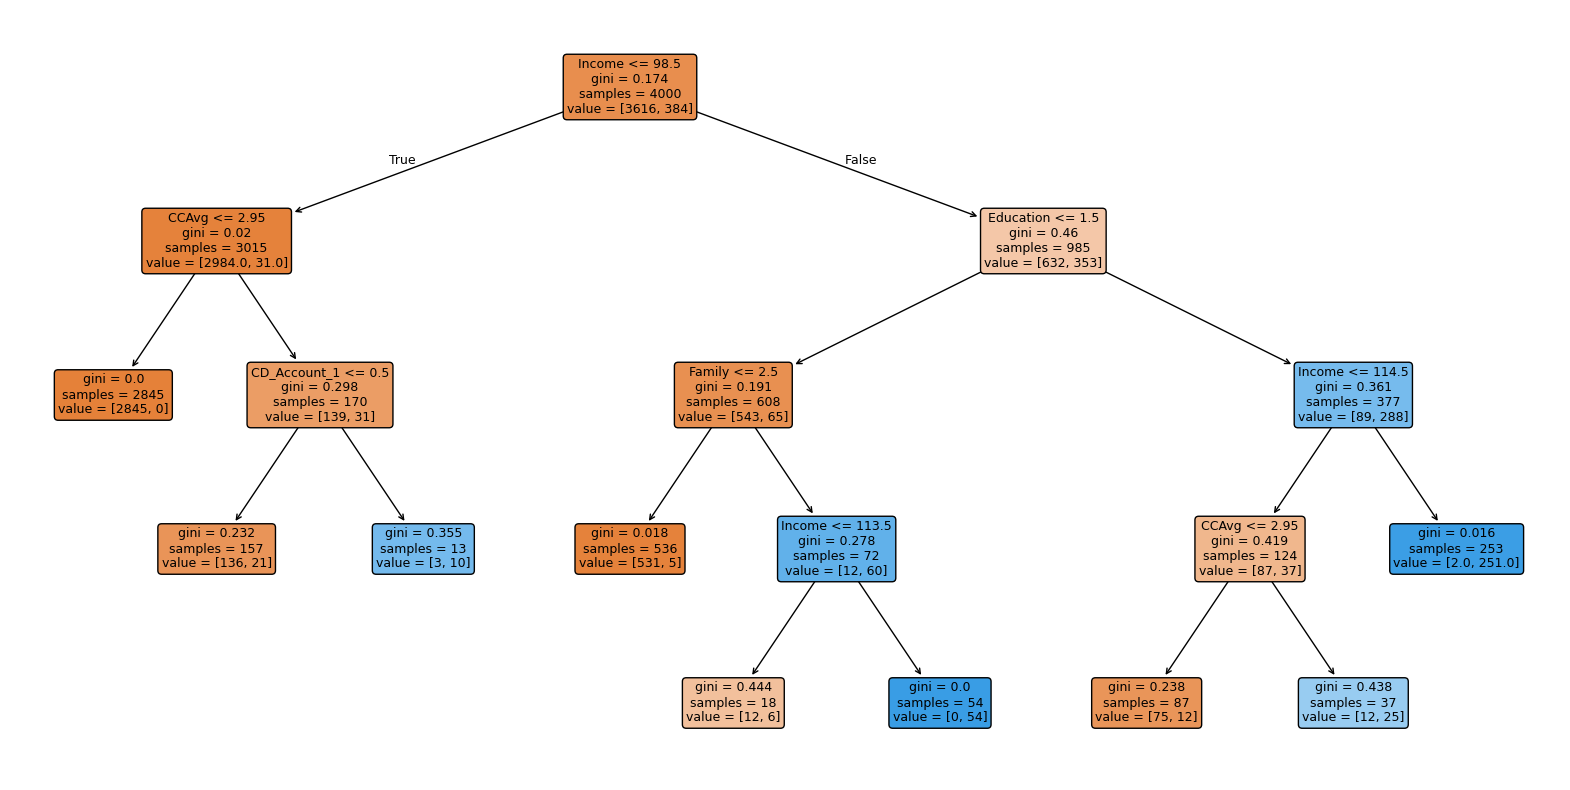

In [ ]:
import sklearn.tree as tree

#visualize decision tree 3
plt.figure(figsize=(20,10))
tree.plot_tree(dtree3, feature_names=X_train.columns, fontsize=9, filled=True, rounded=True)
plt.show()

In [ ]:
# define the parameters of the tree to iterate over
max_depth_values = np.arange(2, 11, 2)
max_leaf_nodes_values = np.arange(10, 51, 10)
min_samples_split_values = np.arange(10, 51, 10)

# initialize variables to store the best model and its performance
best_estimator = None
best_score_diff = float('inf')

# iterate over all combinations of the specified parameter values
for max_depth in max_depth_values:
    for max_leaf_nodes in max_leaf_nodes_values:
        for min_samples_split in min_samples_split_values:

            # initialize the tree with the current set of parameters
            estimator = DecisionTreeClassifier(
                max_depth=max_depth,
                max_leaf_nodes=max_leaf_nodes,
                min_samples_split=min_samples_split,
                random_state=42
            )

            # fit the model to the training data
            estimator.fit(X_train, Y_train)

            # make predictions on the training and test sets
            y_train_pred = estimator.predict(X_train)
            y_test_pred = estimator.predict(X_test)

            # calculate recall scores for training and test sets
            train_recall_score = recall_score(Y_train, y_train_pred)
            test_recall_score = recall_score(Y_test, y_test_pred)

            # calculate the absolute difference between training and test recall scores
            score_diff = abs(train_recall_score - test_recall_score)

            # update the best estimator and best score if the current one has a smaller score difference
            if score_diff < best_score_diff:
                best_score_diff = score_diff
                best_estimator = estimator

#Decision Tree 4 Pre-Pruned for Optimal Recall Score
Decision Tree 4 finds the best hyperperameter to give the least difference between the training recall score and test recall score

In [ ]:
dtree4 = best_estimator
dtree4.fit(X_train, Y_train)

DecisionTreeClassifier(max_depth=np.int64(10), max_leaf_nodes=np.int64(50),
                       min_samples_split=np.int64(10), random_state=42)

#Decision Tree 4 Performance Metrics

In [ ]:
dtree4_perf = model_performance_classification(dtree4, X_train, Y_train)
dtree4_perf

,Accuracy:,Recall:,Precision:,F1:
0,0.99275,0.945312,0.978437,0.961589


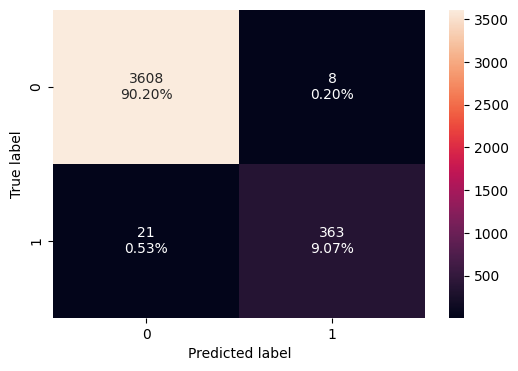

In [ ]:
plot_confusion_matrix(dtree4, X_train, Y_train)

In [ ]:
dtree4_perf = model_performance_classification(dtree4, X_test, Y_test)
dtree4_perf

,Accuracy:,Recall:,Precision:,F1:
0,0.986,0.947917,0.91,0.928571


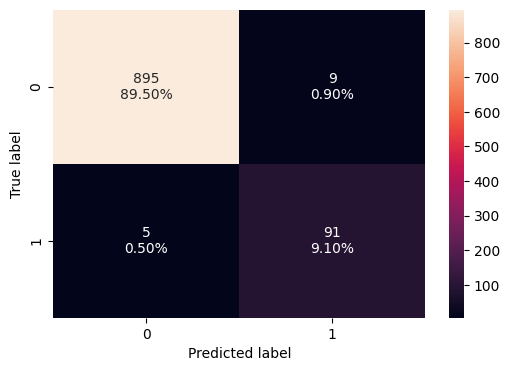

In [ ]:
plot_confusion_matrix(dtree4, X_test, Y_test)

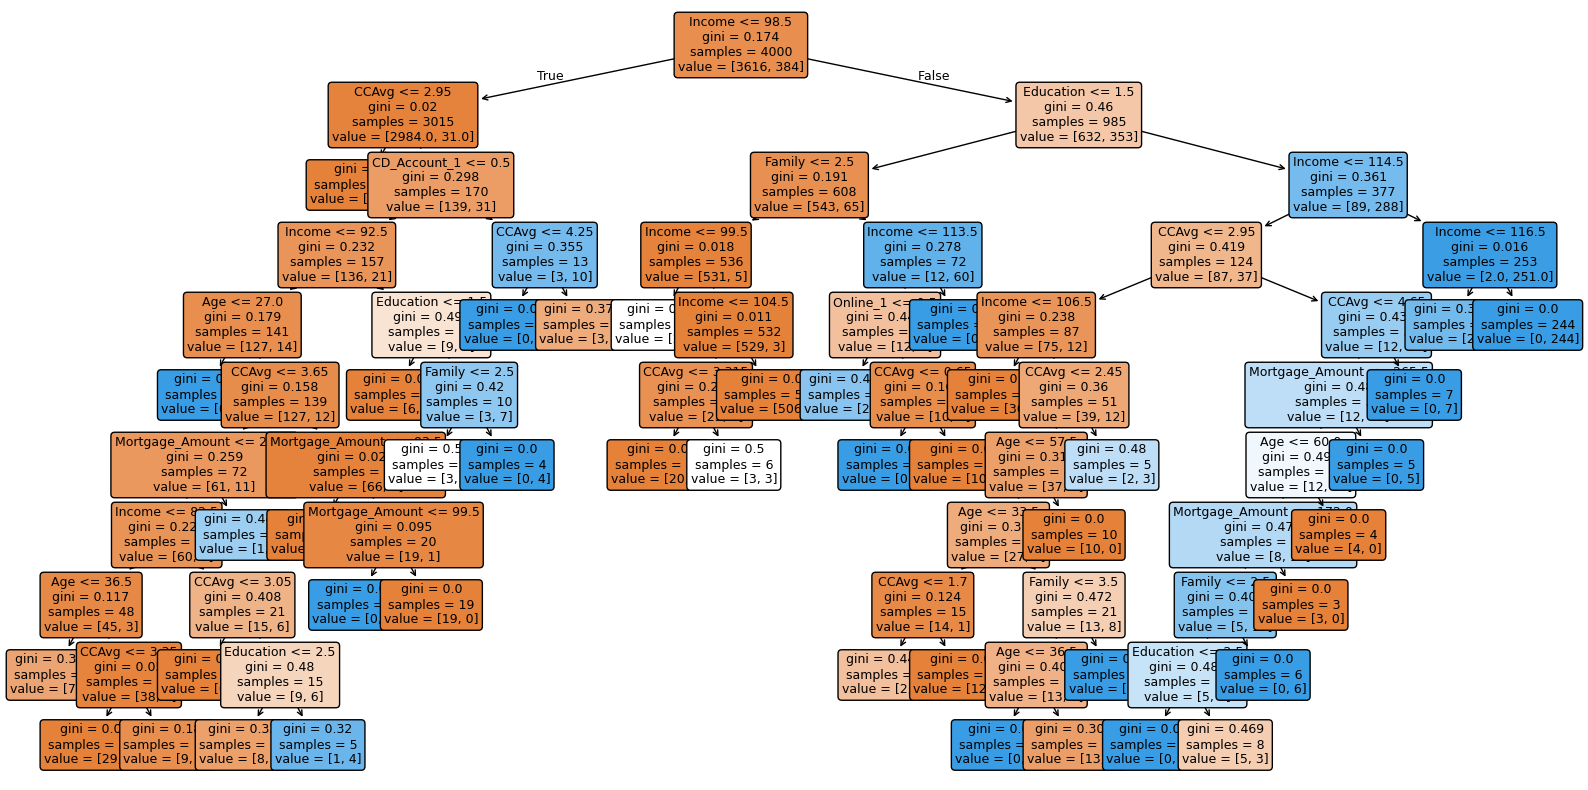

In [ ]:
import sklearn.tree as tree

#visualize decision tree4
plt.figure(figsize=(20,10))
tree.plot_tree(dtree4, feature_names=X_train.columns, fontsize=9, filled=True, rounded=True)
plt.show()

## Model Performance Comparison and Final Model Selection

In [ ]:
#training performance comparison

#save decision tree performance for training
dtree_performance_tree1_train = model_performance_classification(dtree1, X_train, Y_train)
dtree_performance_tree2_train = model_performance_classification(dtree2, X_train, Y_train)
dtree_performance_tree3_train = model_performance_classification(dtree3, X_train, Y_train)
dtree_performance_tree4_train = model_performance_classification(dtree4, X_train, Y_train)

#create dataframe to compare training data performance
model_training_comparision = pd.concat([
    dtree_performance_tree1_train.T,
    dtree_performance_tree2_train.T,
    dtree_performance_tree4_train.T,
    dtree_performance_tree3_train.T,
],
  axis=1
)
model_training_comparision.columns = ["Decision Tree (sklearn default)", "Decision Tree (Pre-Pruning for Precision)", "Decision Tree (Pre-Pruing for Recall)", "Decision Tree(Post-Pruning)"]
print("Models on Training Set")
model_training_comparision

Models on Training Set


,Decision Tree (sklearn default),Decision Tree (Pre-Pruning for Precision),Decision Tree (Pre-Pruing for Recall),Decision Tree(Post-Pruning)
Accuracy:,1.0,0.984750,0.992750,0.984750
Recall:,1.0,0.885417,0.945312,0.885417
Precision:,1.0,0.952381,0.978437,0.952381
F1:,1.0,0.917679,0.961589,0.917679


In [ ]:
#training performance comparison

#save decision tree performance for test
dtree_performance_tree1_test = model_performance_classification(dtree1, X_test, Y_test)
dtree_performance_tree2_test = model_performance_classification(dtree2, X_test, Y_test)
dtree_performance_tree3_test = model_performance_classification(dtree3, X_test, Y_test)
dtree_performance_tree4_test = model_performance_classification(dtree4, X_test, Y_test)

#Create Dataframe comparing test data performance
model_training_comparision = pd.concat([
    dtree_performance_tree1_test.T,
    dtree_performance_tree2_test.T,
    dtree_performance_tree4_test.T,
    dtree_performance_tree3_test.T,
],
  axis=1
)
model_training_comparision.columns = ["Decision Tree (sklearn default)", "Decision Tree (Pre-Pruning for Precision)", "Decision Tree (Pre_Pruning for Recall)" ,"Decision Tree (Post-Pruning)"]
print("Models on Test Set")
model_training_comparision

Models on Test Set


,Decision Tree (sklearn default),Decision Tree (Pre-Pruning for Precision),Decision Tree (Pre_Pruning for Recall),Decision Tree (Post-Pruning)
Accuracy:,0.982000,0.991000,0.986000,0.991000
Recall:,0.947917,0.958333,0.947917,0.958333
Precision:,0.875000,0.948454,0.910000,0.948454
F1:,0.910000,0.953368,0.928571,0.953368


#Observations and Final Model Selection
### Observations

Four decision tree models were developed and evaluated: the default Scikit-learn decision tree, a pre-pruned tree optimized for precision, a pre-pruned tree optimized for recall, and a post-pruned tree. The default Scikit-learn model demonstrated signs of overfitting, as it performed very well on the training data but showed reduced generalization on the test data. This indicates that the model was too complex and captured noise rather than meaningful patterns.

The pre-pruned model optimized for precision and the post-pruned model produced the exact same tree structure. This suggests that the pre-pruning parameters selected the mathematically optimal stopping point during training, eliminating the need for additional post-pruning. Because both methods converged to the same solution, the precision-focused pre-pruned tree is considered the optimal model.

From a business perspective, prioritizing precision is the most appropriate strategy for the bank. A higher precision score means the model is more accurate when identifying qualified loan applicants and reduces the likelihood of approving loans for unqualified individuals. This directly helps minimize loan defaults, reduce financial losses, and improve long-term profitability through more reliable interest revenue.

The final selected model achieved strong performance on the test dataset with the following evaluation metrics:

* Accuracy: 0.991
* Recall: 0.9583
* Precision: 0.9484
* F1-Score: 0.95

These results demonstrate that the model provides an excellent balance between predictive performance and business risk management.

### Final Model Selection

The final model selected is the pre-pruned decision tree optimized for precision (Tree #2). This model was chosen because it avoided the overfitting observed in the default Scikit-learn tree while achieving the same optimal structure as the post-pruned model. Its strong precision performance aligns with the bank’s objective of reducing the approval of high-risk loans. Additionally, the model maintained high overall predictive accuracy and balanced performance across all evaluation metrics, making it the most effective and business-relevant solution.


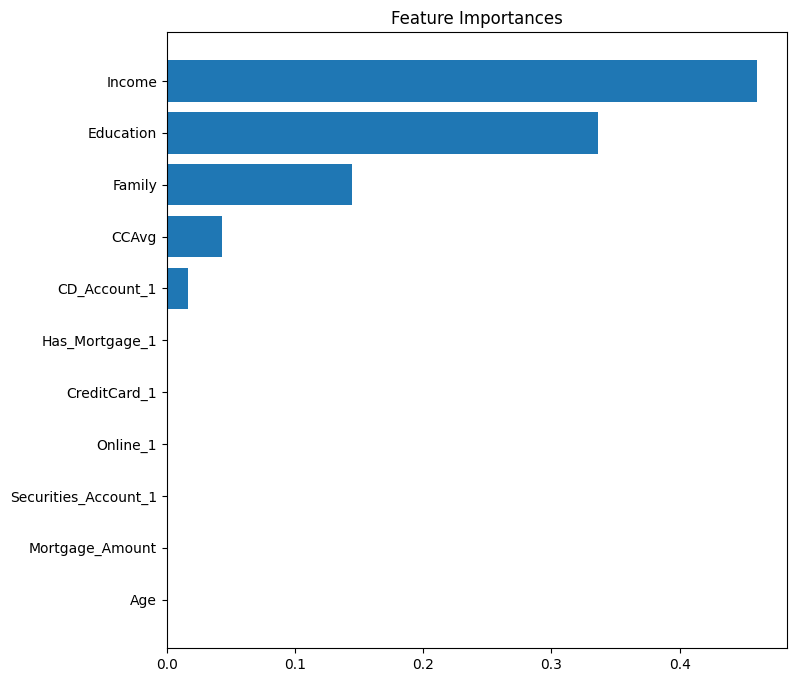

In [ ]:
#importance of features in the tree building
importances = dtree2.feature_importances_
indices = np.argsort(importances)

#plot graph
plt.figure(figsize=(8,8));
plt.title('Feature Importances');
plt.barh(range(len(indices)), importances[indices]);
plt.yticks(range(len(indices)), [X_train.columns[i] for i in indices] );

#Most Important Features in decision tree 2


*   The most important features to determine loan acceptance is as follows Income (1), Education (2), Family (3), CCAvg (4),Active CD Account (5)
*   Features that create a lot of noise include having a mortgage, having a credit card with another bank, using online banking, having a securities account, size of mortgage if having one, and age.



In [ ]:
#output computation time
%%time

# choosing a data point
applicant_details = X_test.sample(n=1, random_state=None)

# saving the original index to look up their actual features if needed
applicant_id = applicant_details.index[0]

#making a prediction
approval_prediction = dtree2.predict(applicant_details)

#mapping the prediction to a human readable output
status = 'Approved' if approval_prediction == 1 else 'Not Approved'
print("testing applicant ID:", applicant_id)
print("Loan applicant prediction:", status)
print('Computation Metrics:')

testing applicant ID: 2752
Loan applicant prediction: Not Approved
Computation Metrics:
CPU times: user 3.98 ms, sys: 0 ns, total: 3.98 ms
Wall time: 3.9 ms


# Actionable Insights and Business Recommendations

To improve the effectiveness of future marketing campaigns, the bank should focus primarily on customers with incomes greater than 98.5k. The analysis showed that most customers below this income level were unlikely to accept or qualify for a personal loan, meaning marketing efforts toward those groups would likely produce lower returns and unnecessary marketing costs. Loan acceptance rates increased even further among customers with higher education levels, especially those with education beyond a bachelor’s degree. Based on the analysis, income and education were the two strongest indicators of personal loan interest and acceptance.

The results also showed that most existing liability products had little impact on loan interest, except for credit card spending behavior. However, customers who held CD accounts showed a much stronger likelihood of accepting a personal loan offer. Because of this, the bank should prioritize CD account holders, especially those actively using the online banking portal, in future loan advertising campaigns and personalized outreach efforts.

The final model performed very strongly, achieving an accuracy score of 99.1%, recall of 95.83%, precision of 94.84%, and an F1-score of 95%. These results indicate that the bank can confidently use the model to better identify customers who are most likely to respond positively to personal loan offers. By focusing marketing efforts on these higher-probability customers, the bank can improve campaign conversion rates, reduce wasted marketing spend, and support more profitable loan portfolio growth.


___